# Extract features

Embeddings for 1,000 images drawn at random from the 13,000 labelled STL-10 samples.

A Vision Transformer does not look at an image as a whole. It cuts it into patches, turns
each patch into a vector. We keep that vector and thus have 768 numbers per
image.

We take it at several depths. The chosen indices are saved alongside the embeddings, so every later task uses
exactly the same 1,000 images.

Output: `data/embeddings_stl10_1000.npz` with `idx`, `y` and `E_l<layer>`.

In [1]:
import numpy as np
from pathlib import Path

DATA = "data/stl10_binary"
IMG = 96
N = 1000
SEED = 0

def load_rgb(split):
    X = np.fromfile(f"{DATA}/{split}_X.bin", dtype=np.uint8).reshape(-1, 3, IMG, IMG)
    return X.transpose(0, 3, 2, 1)

def load_y(split):
    return np.fromfile(f"{DATA}/{split}_y.bin", dtype=np.uint8)

X_all = np.concatenate([load_rgb("train"), load_rgb("test")])
y_all = np.concatenate([load_y("train"), load_y("test")])

rng = np.random.default_rng(SEED)
idx = np.sort(rng.choice(len(X_all), N, replace=False))

X = X_all[idx]
y = y_all[idx]

print(X_all.shape, "->", X.shape)

(13000, 96, 96, 3) -> (1000, 96, 96, 3)


In [2]:
import torch
from PIL import Image
from transformers import AutoImageProcessor, AutoModel

MODEL = "meganariley/wildflower-classifier-vit"

processor = AutoImageProcessor.from_pretrained(MODEL)
model = AutoModel.from_pretrained(MODEL).eval()

torch.set_num_threads(2)

print(type(model).__name__, "| layers:", model.config.num_hidden_layers)

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.00k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: meganariley/wildflower-classifier-vit
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ViTModel | layers: 12


In [3]:
LAYERS = [1, 2, 3, 6, 9, 12]      # 0 is the patch embedding: identical for every image

@torch.inference_mode()
def embed(images, batch_size=32):
    out = {k: [] for k in LAYERS}
    for start in range(0, len(images), batch_size):
        batch = [Image.fromarray(im) for im in images[start:start + batch_size]]
        hs = model(**processor(images=batch, return_tensors="pt"),
                   output_hidden_states=True).hidden_states
        for k in LAYERS:
            out[k].append(hs[k][:, 0].float().numpy())
        if start % (batch_size * 5) == 0:
            print(f"  {start:,} / {len(images):,}", flush=True)
    return {k: np.vstack(v) for k, v in out.items()}

In [4]:
EMB = Path("data/embeddings_stl10_1000.npz")

if EMB.exists():
    print(f"loaded {EMB} - skipped")
else:
    E = embed(X)
    np.savez_compressed(
        EMB, idx=idx, y=y,
        **{f"E_l{k}": v.astype(np.float32) for k, v in E.items()},
    )
    print(f"saved {EMB}")

d = np.load(EMB)
print({k: d[k].shape for k in d.files})

  0 / 1,000
  160 / 1,000
  320 / 1,000
  480 / 1,000
  640 / 1,000
  800 / 1,000
  960 / 1,000
saved data/embeddings_stl10_1000.npz
{'idx': (1000,), 'y': (1000,), 'E_l1': (1000, 768), 'E_l2': (1000, 768), 'E_l3': (1000, 768), 'E_l6': (1000, 768), 'E_l9': (1000, 768), 'E_l12': (1000, 768)}


# Quick tests

class 3: images 3 and 19 -> cosine 0.982


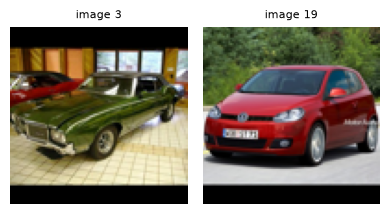

In [5]:
import matplotlib.pyplot as plt

LAYER = 3
E = d[f"E_l{LAYER}"]

c = y[3]
i, j = np.where(y == c)[0][:2]

cos = E[i] @ E[j] / (np.linalg.norm(E[i]) * np.linalg.norm(E[j]))
print(f"class {c}: images {i} and {j} -> cosine {cos:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(4, 2.2))

for ax, k in zip(axes, (i, j)):
    ax.imshow(X[k])
    ax.set_title(f"image {k}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

classes 6 and 3: images 6 and 3 -> cosine 0.958


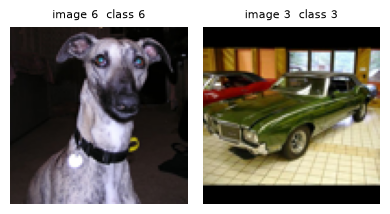

In [6]:
import matplotlib.pyplot as plt

LAYER = 3
E = d[f"E_l{LAYER}"]

i = 6
j = 3          # first image of a different class

cos = E[i] @ E[j] / (np.linalg.norm(E[i]) * np.linalg.norm(E[j]))
print(f"classes {y[i]} and {y[j]}: images {i} and {j} -> cosine {cos:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(4, 2.2))

for ax, k in zip(axes, (i, j)):
    ax.imshow(X[k])
    ax.set_title(f"image {k}  class {y[k]}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Quick test (later layer)

class 3: images 3 and 19 -> cosine 0.518


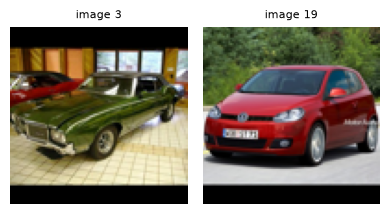

In [7]:
import matplotlib.pyplot as plt

LAYER = 12
E = d[f"E_l{LAYER}"]

c = y[3]
i, j = np.where(y == c)[0][:2]

cos = E[i] @ E[j] / (np.linalg.norm(E[i]) * np.linalg.norm(E[j]))
print(f"class {c}: images {i} and {j} -> cosine {cos:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(4, 2.2))

for ax, k in zip(axes, (i, j)):
    ax.imshow(X[k])
    ax.set_title(f"image {k}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

classes 6 and 3: images 6 and 3 -> cosine 0.111


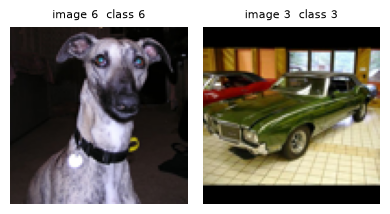

In [8]:
import matplotlib.pyplot as plt

LAYER = 12
E = d[f"E_l{LAYER}"]

i = 6
j = 3          # first image of a different class

cos = E[i] @ E[j] / (np.linalg.norm(E[i]) * np.linalg.norm(E[j]))
print(f"classes {y[i]} and {y[j]}: images {i} and {j} -> cosine {cos:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(4, 2.2))

for ax, k in zip(axes, (i, j)):
    ax.imshow(X[k])
    ax.set_title(f"image {k}  class {y[k]}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()